# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.fm KMeans Clustering and Principal Component Analysis Notebook (WIP)

*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 2nd November 2026*

---

## Research question

**Do the tracks I have listened to group into clusters by Spotify audio features, and do those clusters line up with my top ten listened to artists?**

Uses ten audio features taken from the merged hugging face dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import seaborn as sns; sns.set()


audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration']

plays = pd.read_csv('../datasets/scrobbles.csv')
tracks = pd.read_csv('../datasets/scrobbled_merged_with_hugging_face.csv')

Top ten most scrobbled artists

In [2]:
top_artists = plays['artist'].value_counts().head(10).index
subset = tracks[tracks['artist'].isin(top_artists)].copy()

print(subset['artist'].value_counts())
print(subset[audio].describe().round(2))

artist
Red Hot Chili Peppers    180
John Mayer                74
Arctic Monkeys            68
Pink Floyd                57
Tame Impala               55
Ghost                     50
Alice in Chains           43
Portishead                32
Morcheeba                 26
Massive Attack            11
Name: count, dtype: int64
       danceability  energy  loudness  speechiness  acousticness  \
count        596.00  596.00    596.00       596.00        596.00   
mean           0.51    0.67     -7.86         0.06          0.18   
std            0.15    0.24      4.63         0.04          0.26   
min            0.13    0.01    -35.90         0.02          0.00   
25%            0.41    0.50     -9.95         0.03          0.01   
50%            0.53    0.72     -6.60         0.04          0.04   
75%            0.62    0.87     -5.00         0.06          0.25   
max            0.94    1.00     -0.32         0.46          0.99   

       instrumentalness  liveness  valence   tempo  duration  
c

Because `loudness`, `tempo` and `duration` have much bigger scales than the 0 - 1 features, rescaling is applied using `StandardScaler` 

In [3]:
X = subset[audio]
X_scaled = StandardScaler().fit_transform(X)

# artist as integer labels, like digits.target
y_true, artist_names = pd.factorize(subset['artist'])

Ten clusters, one for each artist out my top 10 artists

In [4]:
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(X_scaled)
kmeans.cluster_centers_.shape

(10, 10)

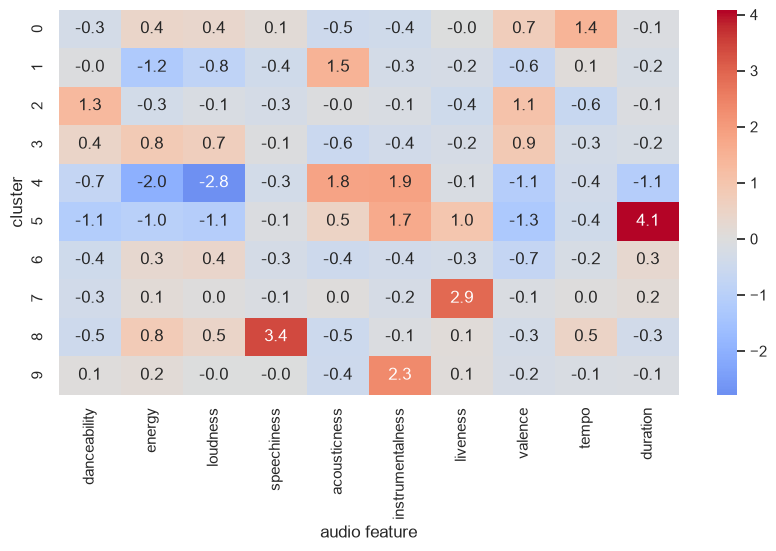

In [5]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=audio)
plt.figure(figsize=(10, 5))
sns.heatmap(centers, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.xlabel('audio feature')
plt.ylabel('cluster');

Project to two dimensions with `PCA`

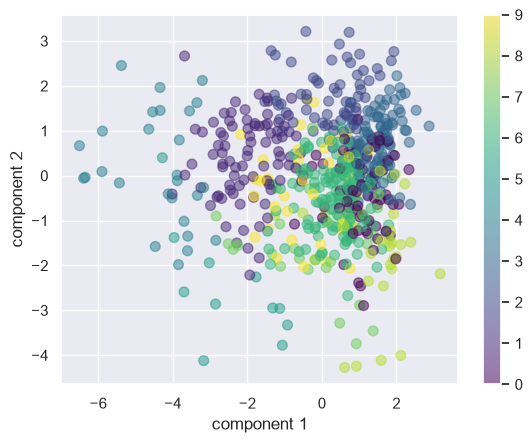

In [6]:
pca = PCA(2)
projected = pca.fit_transform(X_scaled)

plt.scatter(projected[:, 0], projected[:, 1],
            c=clusters, s=50, alpha=0.5, cmap='viridis')
plt.xlabel('component 1')
plt.ylabel('component 2')
plt.colorbar();

In [8]:
labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = np.bincount(y_true[mask]).argmax()

baseline = np.bincount(y_true).max() / len(y_true)
print('Baseline accuracy:', baseline)
print('Cluster accuracy: ', accuracy_score(y_true, labels))

Baseline accuracy: 0.30201342281879195
Cluster accuracy:  0.38926174496644295


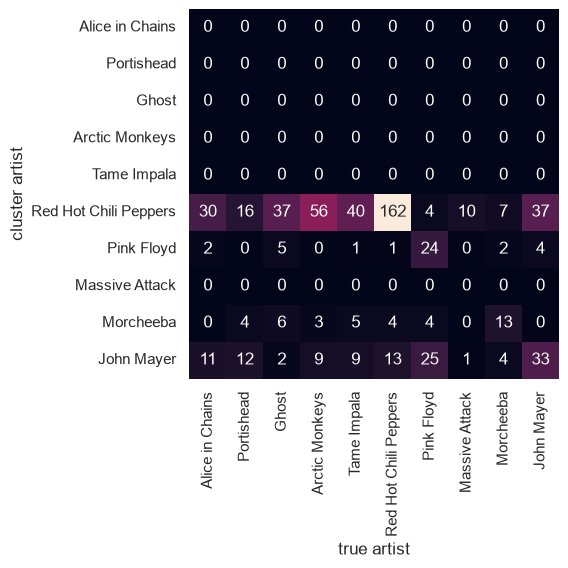

In [9]:
mat = confusion_matrix(y_true, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=artist_names, yticklabels=artist_names)
plt.xlabel('true artist')
plt.ylabel('cluster artist');